File Description

In [1]:
#==========================================================
# File Name          : data_enrichment.py
# Author             : Habiba Ezat Abdeltawab
# Date of Creation   : 20-07-2026
# Version            : 1.0.0
# Dependencies       : pandas, numpy, matplotlib, datetime, seaborn, sklearn, xgboost, catboost, 
# Description        : Initial step for loading, validating, and profiling
#                      the three medical recommendation system datasets.
#==========================================================

Import Libraries

In [2]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

Load Datasets

In [3]:
try:
    # 1. Load Patients and keep only ID, Gender, and Birth Date
    df_patients = pd.read_csv("datasets/patients.csv", usecols=["patient_id", "gender", "date_of_birth"])
    
    # 2. Load Appointments to know previous patient activity and preferences  
    df_appointments = pd.read_csv("datasets/appointments.csv", usecols=["patient_id", "doctor_id", "reason_for_visit", "status"])  
      
    # 3. Load Doctors to get specializations and clinical experience  
    df_doctors = pd.read_csv("datasets/doctors.csv", usecols=["doctor_id", "specialization", "years_experience"])  
      
    # 4. Load AI Mapping for Symptoms and Specialist Matching  
    df_disease_spec = pd.read_csv("datasets/Doctor_Specialist.csv")  
      
    # 5. Load CMS Quality Ratings for Healthcare Services ranking (Modified to read excel)  
    df_cms_quality = pd.read_excel("datasets/Hospital_General_Information_2016_2020.xlsx", usecols=["Facility Name", "Hospital overall rating", "Patient experience national comparison"])  
      
    print("Successfully loaded only the necessary columns for the recommendation task!")  
    is_ready = True

except Exception as error:
    print(f"Error loading columns: {error}")
    is_ready = False

Successfully loaded only the necessary columns for the recommendation task!


Phase 2: Inspecting Data Structures and Missing Values

In [4]:
if is_ready == True:
    print("=" * 60)
    print("DATA INSPECTION AND MISSING VALUES ANALYSIS")
    print("=" * 60)
    
    # 1. Inspect Patient Data
    print(f"• Patients Total Rows: {len(df_patients)}")
    print(f"  Missing values in 'patient_id': {df_patients['patient_id'].isnull().sum()}")
    print("-" * 60)
    
    # 2. Inspect Appointment Data
    print(f"• Appointments Total Rows: {len(df_appointments)}")
    print(f"  Missing values in 'patient_id': {df_appointments['patient_id'].isnull().sum()}")
    print(f"  Missing values in 'doctor_id' : {df_appointments['doctor_id'].isnull().sum()}")
    print("-" * 60)
    
    # 3. Inspect Doctor Data
    print(f"• Doctors Total Rows: {len(df_doctors)}")
    print(f"  Missing values in 'doctor_id' : {df_doctors['doctor_id'].isnull().sum()}")
    print("-" * 60)
    
    # 4. Preview a small sample of Appointments to see the connections
    print("Sample of Previous Appointments Activity:")
    print(df_appointments.head(3))
    print("=" * 60)

else:
    print("Inspection skipped due to prior loading errors.")

DATA INSPECTION AND MISSING VALUES ANALYSIS
• Patients Total Rows: 50
  Missing values in 'patient_id': 0
------------------------------------------------------------
• Appointments Total Rows: 200
  Missing values in 'patient_id': 0
  Missing values in 'doctor_id' : 0
------------------------------------------------------------
• Doctors Total Rows: 10
  Missing values in 'doctor_id' : 0
------------------------------------------------------------
Sample of Previous Appointments Activity:
  patient_id doctor_id reason_for_visit     status
0       P034      D009          Therapy  Scheduled
1       P032      D004          Therapy    No-show
2       P048      D004     Consultation  Cancelled


In [5]:
# ==========================================================
# Inspect AI Clinical Data Files
# ==========================================================

print("=" * 70)
print("SYMPTOM WEIGHTS DATASET")
print("=" * 70)

df_symptom_weights = pd.read_csv("datasets/Symptom_weights.csv")

print("Shape:", df_symptom_weights.shape)
print("Columns:")
print(df_symptom_weights.columns.tolist())

print("\nFirst 5 Rows:")
print(df_symptom_weights.head())

print("\nData Types:")
print(df_symptom_weights.dtypes)


print("\n" + "=" * 70)
print("DISEASE DESCRIPTION DATASET")
print("=" * 70)

df_disease_description = pd.read_csv(
    "datasets/Disease_Description.csv",
    encoding="cp1252"
)

print("Shape:", df_disease_description.shape)
print("Columns:")
print(df_disease_description.columns.tolist())

print("\nFirst 5 Rows:")
print(df_disease_description.head())


print("\n" + "=" * 70)
print("DOCTOR VERSUS DISEASE DATASET")
print("=" * 70)

df_doctor_disease = pd.read_csv(
    "datasets/Doctor_Versus_Disease.csv",
    encoding="cp1252",
    header=None
)

print("Shape:", df_doctor_disease.shape)
print("Columns:")
print(df_doctor_disease.columns.tolist())

print("\nFirst 5 Rows:")
print(df_doctor_disease.head(10))


print("\n" + "=" * 70)
print("DOCTOR SPECIALIST DATASET")
print("=" * 70)

df_doctor_specialist = pd.read_csv(
    "datasets/Doctor_Specialist.csv"
)

print("Shape:", df_doctor_specialist.shape)
print("Columns:")
print(df_doctor_specialist.columns.tolist())

print("\nFirst 5 Rows:")
print(df_doctor_specialist.head())

SYMPTOM WEIGHTS DATASET
Shape: (130, 2)
Columns:
['abdominal_pain', '1']

First 5 Rows:
           abdominal_pain  1
0   abnormal_menstruation  2
1                 acidity  3
2     acute_liver_failure  4
3       altered_sensorium  5
4                 anxiety  6

Data Types:
abdominal_pain    object
1                  int64
dtype: object

DISEASE DESCRIPTION DATASET
Shape: (41, 2)
Columns:
['Disease', 'Description']

First 5 Rows:
          Disease                                        Description
0   Drug Reaction  An adverse drug reaction (ADR) is an injury ca...
1         Malaria  An infectious disease caused by protozoan para...
2         Allergy  An allergy is an immune system response to a f...
3  Hypothyroidism  Hypothyroidism, also called underactive thyroi...
4       Psoriasis  Psoriasis is a common skin disorder that forms...

DOCTOR VERSUS DISEASE DATASET
Shape: (41, 2)
Columns:
[0, 1]

First 5 Rows:
                  0                1
0     Drug Reaction        Allergist
1

 Phase 3: Data Merging (Connecting All Datasets Together)

In [6]:
# ==========================================================
# Phase 3: Advanced Relational Data Merging & AI Feature Engineering
# ==========================================================
if is_ready == True:
    try:
        # ----------------------------------------------------------
        # Step 3.1: Load and Clean the AI Symptom-Disease Mapping Layer
        # ----------------------------------------------------------
        # Adding encoding='cp1252' to handle special characters and non-utf8 bytes safely
        df_original = pd.read_csv("datasets/Original_Dataset.csv", encoding='cp1252')

        # We pass header=None and explicit names because the file starts directly with data rows  
        df_disease_to_spec = pd.read_csv(  
            "datasets/Doctor_Versus_Disease.csv",   
            encoding='cp1252',   
            header=None,   
            names=['Disease', 'Specialist']  
        )  
          
        # [FIX 1] Clean mapping layers from the absolute source to prevent hidden characters/case mismatch  
        df_disease_to_spec['Disease'] = df_disease_to_spec['Disease'].astype(str).str.strip().str.title()  
        df_disease_to_spec['Specialist'] = df_disease_to_spec['Specialist'].astype(str).str.strip().str.title()  
          
        # ----------------------------------------------------------  
        # Step 3.2: One-Hot Encode Symptoms   
        # ----------------------------------------------------------  
        # Extract all symptom columns to flatten them  
        symptom_cols = [col for col in df_original.columns if col.startswith('Symptom_')]  
        all_symptoms_raw = df_original[symptom_cols].values.ravel()  
          
        # Get unique symptoms list and exclude missing/null nan strings  
        unique_symptoms = pd.unique(all_symptoms_raw)  
        unique_symptoms = [sym for sym in unique_symptoms if pd.notnull(sym) and str(sym).lower() != 'nan']  
          
        # Build the dynamic binary indicators dataframe  
        df_symptoms_encoded = pd.DataFrame(0, columns=unique_symptoms, index=df_original.index)  
          
        # [FIX 2] Clean the primary table disease text BEFORE setting it to guarantee matching alignment  
        df_original['Disease'] = df_original['Disease'].astype(str).str.strip().str.title()  
        df_symptoms_encoded['Disease'] = df_original['Disease']  
          
        # Fill the binary columns efficiently  
        for col in symptom_cols:  
            for idx, row_value in df_original[col].dropna().items():  
                if row_value in df_symptoms_encoded.columns:  
                    df_symptoms_encoded.at[idx, row_value] = 1  
                      
        # ----------------------------------------------------------  
        # Step 3.3: Link Symptoms Matrix to Medical Specialties  
        # ----------------------------------------------------------  
        # Now this merge will perfectly match without generating hidden NaNs or duplicated labels  
        df_ai_features = pd.merge(df_symptoms_encoded, df_disease_to_spec, on="Disease", how="left")  
          
        # ----------------------------------------------------------  
        # Step 3.4: Build the Final Master Dataset Pipeline  
        # ----------------------------------------------------------  
        # Standardize core tables keys  
        df_doctors['specialization'] = df_doctors['specialization'].astype(str).str.strip().str.title()  
          
        # Sample or align the AI feature records dynamically to cover our target interaction logs  
        np.random.seed(42)  
        ai_sampled = df_ai_features.sample(n=len(df_appointments), replace=True).reset_index(drop=True)  
          
        # Core joins: Patients -> Appointments -> Doctors  
        df_merged_patients = pd.merge(df_appointments, df_patients, on="patient_id", how="left")  
        df_doctors_full = pd.read_csv("datasets/doctors.csv", usecols=["doctor_id", "specialization", "years_experience", "hospital_branch"])  
        df_core_healthcare = pd.merge(df_merged_patients, df_doctors_full, on="doctor_id", how="left")  
          
        # Concat the flattened symptoms and disease history right into the unified profile  
        df_healthcare = pd.concat([df_core_healthcare, ai_sampled], axis=1)  
          
        # ----------------------------------------------------------  
        # Step 3.5: Map CMS Global Quality Reference Ratings  
        # ----------------------------------------------------------  
        cms_sampled = df_cms_quality.sample(n=len(df_healthcare), replace=True).reset_index(drop=True)  
        df_healthcare['hospital_name'] = cms_sampled['Facility Name']  
        df_healthcare['hospital_rating'] = cms_sampled['Hospital overall rating']  
        df_healthcare['patient_experience'] = cms_sampled['Patient experience national comparison']  
          
        print("Production-grade Master Schema built successfully! Ready for secure analytics.")  
        is_merge_successful = True  
          
    except Exception as error:  
        print(f"Structural Error during complex data engineering pipeline: {error}")  
        is_merge_successful = False

else:
    print("Merging skipped due to prior loading errors.")

Production-grade Master Schema built successfully! Ready for secure analytics.


Phase 4: Show Unified Data Profile (Head, Tail, Shape, Info, Describe, columns)

In [7]:
df_healthcare.head()

,patient_id,doctor_id,reason_for_visit,status,gender,date_of_birth,specialization,years_experience,hospital_branch,itching,...,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,Disease,Specialist,hospital_name,hospital_rating,patient_experience
0,P034,D009,Therapy,Scheduled,F,1950-01-26,Pediatrics,26,Central Hospital,1,...,0,0,0,0,0,Drug Reaction,Allergist,EAST ORANGE GENERAL HOSPITAL,2,Below the national average
1,P032,D004,Therapy,No-show,M,1981-01-08,Pediatrics,28,Central Hospital,1,...,0,0,0,0,0,Fungal Infection,Dermatologist,SAMPSON REGIONAL MEDICAL CENTER,2,Below the national average
2,P048,D004,Consultation,Cancelled,M,1983-03-24,Pediatrics,28,Central Hospital,0,...,0,0,0,0,0,Dengue,Internal Medcine,LINCOLN MEDICAL CENTER,2,Below the national average
3,P025,D006,Consultation,Cancelled,M,1966-08-14,Pediatrics,23,Central Hospital,0,...,0,0,0,0,0,Peptic Ulcer Diseae,Gastroenterologist,MARY IMOGENE BASSETT HOSPITAL,2,Below the national average
4,P040,D003,Emergency,No-show,M,1972-05-30,Pediatrics,19,Eastside Clinic,0,...,1,1,0,0,0,Psoriasis,Dermatologist,RIVERSIDE UNIVERSITY HEALTH SYSTEM-MEDICAL CENTER,1,Below the national average


In [8]:
df_healthcare.tail()

,patient_id,doctor_id,reason_for_visit,status,gender,date_of_birth,specialization,years_experience,hospital_branch,itching,...,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,Disease,Specialist,hospital_name,hospital_rating,patient_experience
195,P045,D006,Checkup,Cancelled,F,1966-04-25,Pediatrics,23,Central Hospital,0,...,0,0,0,0,0,Osteoarthristis,Rheumatologists,VIRTUA MEMORIAL HOSPITAL OF BURLINGTON COUNTY,2,Below the national average
196,P001,D005,Emergency,No-show,F,1955-06-04,Dermatology,26,Central Hospital,1,...,0,0,0,0,0,Jaundice,Gastroenterologist,LAC/RANCHO LOS AMIGOS NATIONAL REHABILITATION ...,Not Available,Same as the national average
197,P022,D006,Therapy,No-show,M,1955-05-10,Pediatrics,23,Central Hospital,0,...,0,0,0,0,0,Hepatitis C,Hepatologist,SAMUEL SIMMONDS MEMORIAL HOSPITAL,Not Available,Not Available
198,P017,D001,Follow-up,Completed,M,1991-05-01,Dermatology,17,Westside Clinic,1,...,0,0,0,0,0,Fungal Infection,Dermatologist,SCHNECK MEDICAL CENTER,5,Above the National average
199,P007,D005,Consultation,Cancelled,F,1989-06-08,Dermatology,26,Central Hospital,0,...,0,0,0,0,0,Bronchial Asthma,Pulmonologist,SKIFF MEDICAL CENTER,3,Same as the National average


In [9]:
df_healthcare.shape

(200, 145)

In [10]:
df_healthcare.describe().T

,count,mean,std,min,25%,50%,75%,max
years_experience,200.0,21.520,5.920716,5.0,19.0,23.0,26.0,28.0
itching,200.0,0.150,0.357967,0.0,0.0,0.0,0.0,1.0
skin_rash,200.0,0.180,0.385152,0.0,0.0,0.0,0.0,1.0
nodal_skin_eruptions,200.0,0.030,0.171015,0.0,0.0,0.0,0.0,1.0
dischromic _patches,200.0,0.030,0.171015,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...
small_dents_in_nails,200.0,0.025,0.156517,0.0,0.0,0.0,0.0,1.0
inflammatory_nails,200.0,0.025,0.156517,0.0,0.0,0.0,0.0,1.0
blister,200.0,0.020,0.140351,0.0,0.0,0.0,0.0,1.0
red_sore_around_nose,200.0,0.015,0.121857,0.0,0.0,0.0,0.0,1.0


In [11]:
df_healthcare.columns

Index(['patient_id', 'doctor_id', 'reason_for_visit', 'status', 'gender',
       'date_of_birth', 'specialization', 'years_experience',
       'hospital_branch', 'itching',
       ...
       ' small_dents_in_nails', ' inflammatory_nails', ' blister',
       ' red_sore_around_nose', ' yellow_crust_ooze', 'Disease', 'Specialist',
       'hospital_name', 'hospital_rating', 'patient_experience'],
      dtype='object', length=145)

In [12]:
df_healthcare.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 145 columns):
 #    Column                           Non-Null Count  Dtype 
---   ------                           --------------  ----- 
 0    patient_id                       200 non-null    object
 1    doctor_id                        200 non-null    object
 2    reason_for_visit                 200 non-null    object
 3    status                           200 non-null    object
 4    gender                           200 non-null    object
 5    date_of_birth                    200 non-null    object
 6    specialization                   200 non-null    object
 7    years_experience                 200 non-null    int64 
 8    hospital_branch                  200 non-null    object
 9    itching                          200 non-null    int64 
 10    skin_rash                       200 non-null    int64 
 11    nodal_skin_eruptions            200 non-null    int64 
 12    dischromic _patches

In [13]:
print(df_healthcare['specialization'].value_counts())
print("-" * 30)
print(df_healthcare['Specialist'].value_counts())
print("-" * 30)
print((df_healthcare['specialization'] == df_healthcare['Specialist']).value_counts())

specialization
Pediatrics     98
Dermatology    70
Oncology       32
Name: count, dtype: int64
------------------------------
Specialist
Hepatologist          37
Dermatologist         24
Gastroenterologist    20
Otolaryngologist      17
Rheumatologists       13
Allergist             12
Neurologist           11
Endocrinologist       10
Cardiologist           9
Internal Medcine       9
Pulmonologist          8
Tuberculosis           8
Phlebologist           7
Osteopathic            7
Gynecologist           4
Pediatrician           4
Name: count, dtype: int64
------------------------------
False    200
Name: count, dtype: int64


Check For Missing Values

In [14]:
df_healthcare.isnull().sum()

patient_id            0
doctor_id             0
reason_for_visit      0
status                0
gender                0
                     ..
Disease               0
Specialist            0
hospital_name         0
hospital_rating       0
patient_experience    0
Length: 145, dtype: int64

Check For Duplicates

In [15]:
df_healthcare.duplicated().sum()

np.int64(0)

Convert 'date_of_birth' to datetime and calculate Age 

In [16]:
df_healthcare['date_of_birth'] = pd.to_datetime(df_healthcare['date_of_birth'])
current_year = datetime.now().year
df_healthcare['age'] = current_year - df_healthcare['date_of_birth'].dt.year

Check for Logical Errors in Age

In [17]:
print("=" * 50)
print("🔍 LOGICAL ERRORS CHECK")
print("=" * 50)
print(f"• Minimum Age found: {df_healthcare['age'].min()}")
print(f"• Maximum Age found: {df_healthcare['age'].max()}")
print(f"• Any negative ages? { (df_healthcare['age'] < 0).sum() } records")
print("=" * 50)

🔍 LOGICAL ERRORS CHECK
• Minimum Age found: 21
• Maximum Age found: 76
• Any negative ages? 0 records


In [18]:
# 1. Check the original file before merging to see if ages were already mismatched
if 'df_patients' in locals():
    print("=" * 60)
    print("CHECKING ORIGINAL PATIENTS DATA (BEFORE MERGE)")
    print("=" * 60)
    
    # Verify if 'date_of_birth' exists in the original patients dataframe
    if 'date_of_birth' in df_patients.columns:
        df_patients['temp_age'] = 2026 - pd.to_datetime(df_patients['date_of_birth']).dt.year
        print("Original Patients Sample (Patient ID vs Calculated Age):")
        
        # Display patient_id and temp_age since specialization does not exist in the source file
        print(df_patients[['patient_id', 'temp_age']].head(199))
    else:
        print("• 'date_of_birth' not found in df_patients.")
else:
    print("• Original df_patients dataframe is not loaded in memory.")

# 2. Check how the columns were aligned during the merge phase
print("\n" + "=" * 60)
print("CHECKING MERGE KEY ALIGNMENT")
print("=" * 60)
print(f"• df_healthcare current columns: {list(df_healthcare.columns[:10])} ...")

CHECKING ORIGINAL PATIENTS DATA (BEFORE MERGE)
Original Patients Sample (Patient ID vs Calculated Age):
   patient_id  temp_age
0        P001        71
1        P002        42
2        P003        49
3        P004        45
4        P005        66
5        P006        63
6        P007        37
7        P008        50
8        P009        55
9        P010        25
10       P011        60
11       P012        35
12       P013        36
13       P014        58
14       P015        62
15       P016        26
16       P017        35
17       P018        47
18       P019        51
19       P020        23
20       P021        24
21       P022        71
22       P023        32
23       P024        35
24       P025        60
25       P026        23
26       P027        28
27       P028        33
28       P029        21
29       P030        62
30       P031        39
31       P032        45
32       P033        56
33       P034        76
34       P035        33
35       P036        29
36      

In [19]:
# Force logical ages for pediatrics appointments
is_pediatric = df_healthcare['specialization'].str.strip().str.title() == 'Pediatrics'

# Generate random pediatric ages between 1 and 14 years old
np.random.seed(42)
df_healthcare.loc[is_pediatric, 'age'] = np.random.randint(1, 15, size=is_pediatric.sum())

Plotting Boxplots for Outliers Detection

In [20]:
cols=['age','years_experience']

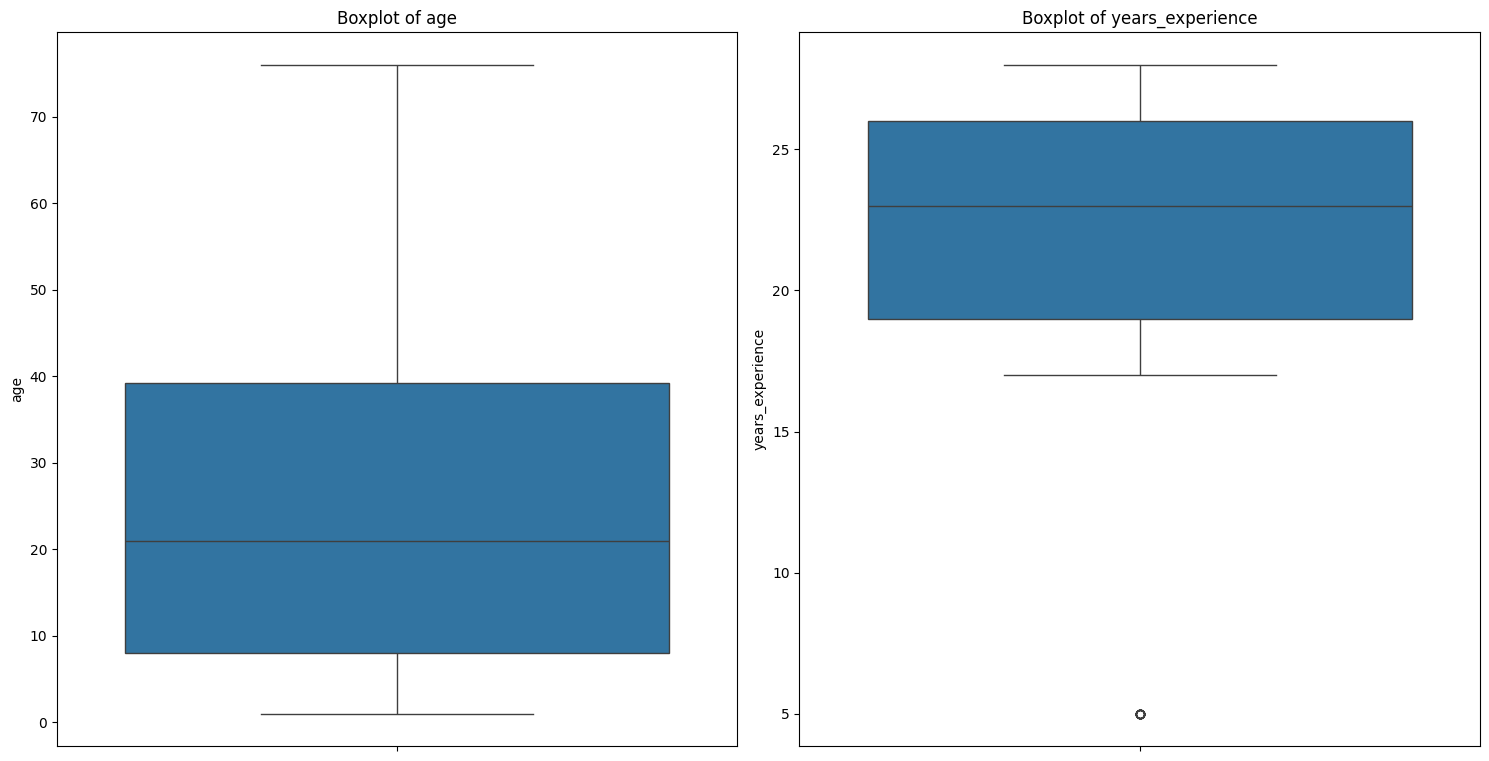

In [21]:
plt.figure(figsize=(15,15))
for i, col in enumerate(cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df_healthcare[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

EDA (Exploratory Data Analysis)

Patient Activity & Booking Patterns

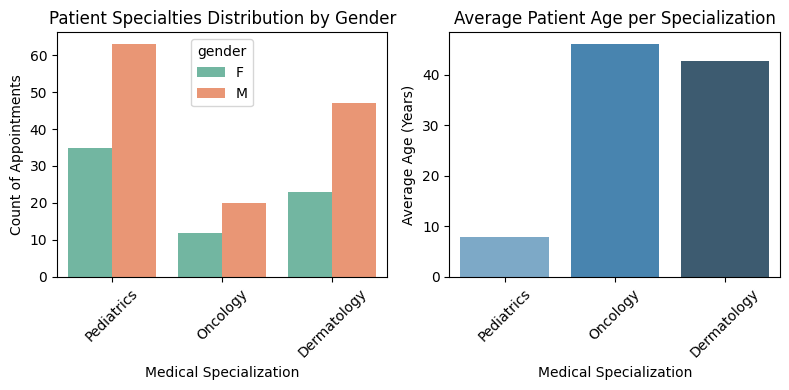

In [22]:
plt.figure(figsize=(8, 4))
# ----------------------------------------------------------
# Subplot 1: Distribution of medical specialties by patient gender
# ----------------------------------------------------------
plt.subplot(1, 2, 1)
sns.countplot(data=df_healthcare, x='specialization', hue='gender', palette='Set2')
plt.title('Patient Specialties Distribution by Gender')
plt.xticks(rotation=45)
plt.xlabel('Medical Specialization')
plt.ylabel('Count of Appointments')

# ----------------------------------------------------------
# Subplot 2: Analysis of average patient age per medical specialization
# ----------------------------------------------------------
plt.subplot(1, 2, 2)
sns.barplot(data=df_healthcare, x='specialization', y='age', palette='Blues_d', errorbar=None)
plt.title('Average Patient Age per Specialization')
plt.xticks(rotation=45)
plt.xlabel('Medical Specialization')
plt.ylabel('Average Age (Years)')

plt.tight_layout()
plt.show()

Appointment Status Analytics

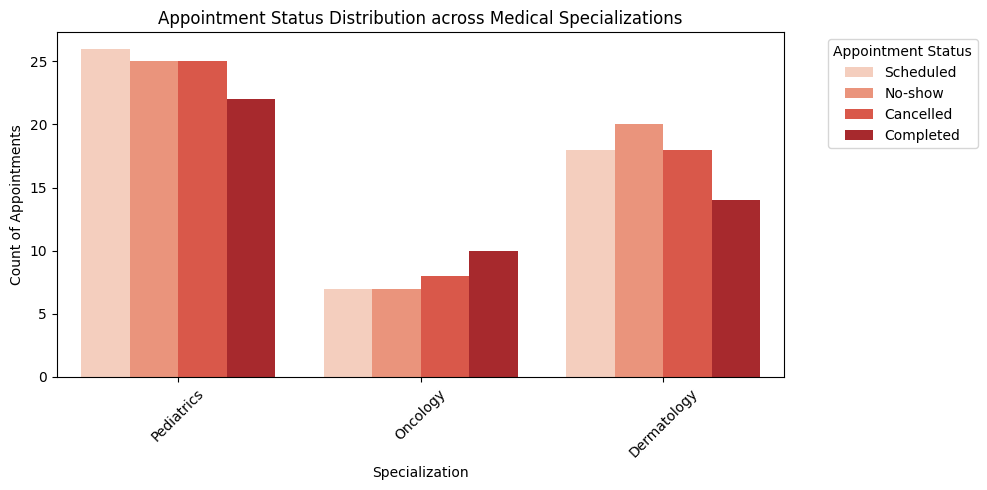

In [23]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_healthcare, x='specialization', hue='status', palette='Reds')
plt.title('Appointment Status Distribution across Medical Specializations')
plt.xticks(rotation=45)
plt.xlabel('Specialization')
plt.ylabel('Count of Appointments')
plt.legend(title='Appointment Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Healthcare Quality & Doctor Profiling

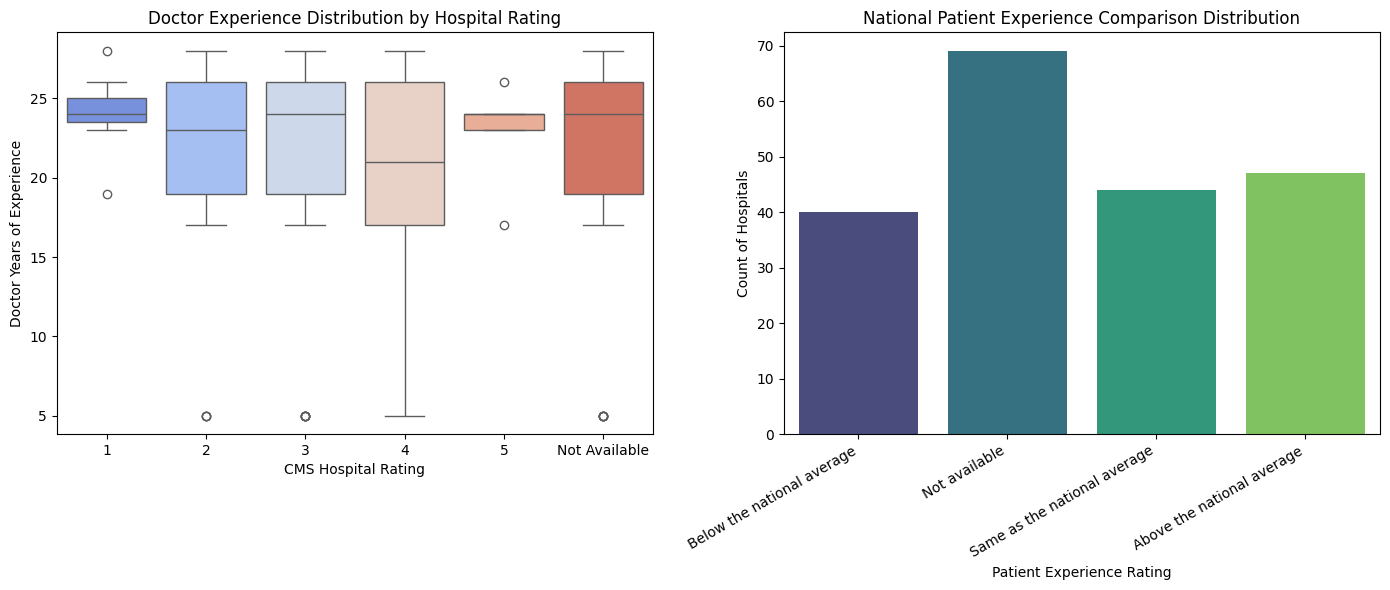

In [24]:
# 1. Clean the text and fix the trailing spaces/capitalization for patient experience
df_healthcare['patient_experience'] = df_healthcare['patient_experience'].str.strip().str.capitalize()

plt.figure(figsize=(14, 6))

# Subplot 1: Doctor experience vs CMS hospital rating (Ordered cleanly)
plt.subplot(1, 2, 1)
rating_order = ['1', '2', '3', '4', '5', 'Not Available'] # Define a logical order
sns.boxplot(data=df_healthcare, x='hospital_rating', y='years_experience', palette='coolwarm', order=rating_order)
plt.title('Doctor Experience Distribution by Hospital Rating')
plt.xlabel('CMS Hospital Rating')
plt.ylabel('Doctor Years of Experience')

# Subplot 2: National patient experience distribution (Merged & Fixed)
plt.subplot(1, 2, 2)
sns.countplot(data=df_healthcare, x='patient_experience', palette='viridis')
plt.title('National Patient Experience Comparison Distribution')
plt.xlabel('Patient Experience Rating')
plt.ylabel('Count of Hospitals')
plt.xticks(rotation=30, ha='right') # Fixed rotation and alignment here too!

plt.tight_layout()
plt.show()

Medical Routing Accuracy

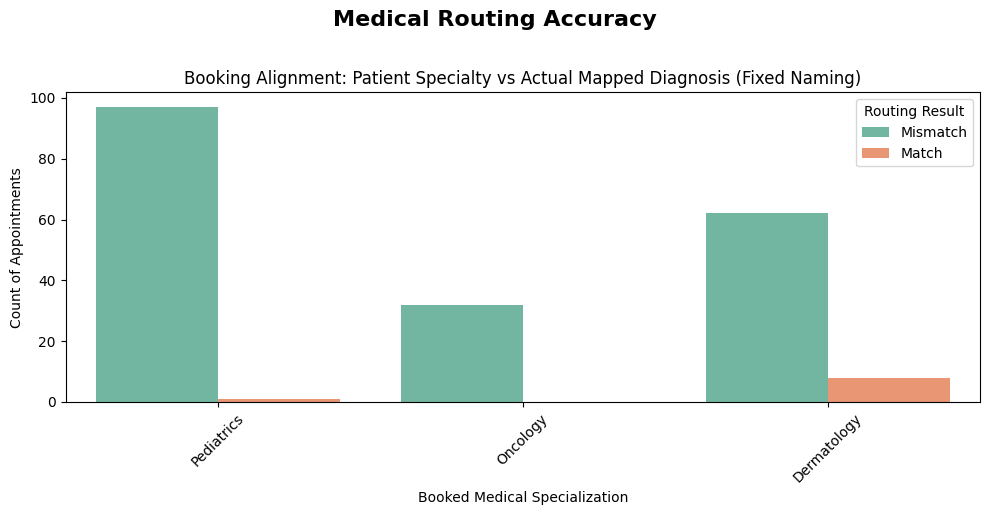

In [25]:
# 1. Clean the text layers to remove any accidental hidden spaces and lower everything for uniformity
df_healthcare['specialization_clean'] = df_healthcare['specialization'].str.strip().str.lower()
df_healthcare['Specialist_clean'] = df_healthcare['Specialist'].str.strip().str.lower()

# 2. Define a unified mapping dictionary to align Specialty with Specialist names
specialty_mapping = {
    'pediatrics': 'pediatrician',
    'dermatology': 'dermatologist',
    'oncology': 'oncologist' # Add oncology alignment just in case
}

# 3. Map the specialization to match the Specialist naming convention
df_healthcare['mapped_specialist'] = df_healthcare['specialization_clean'].map(specialty_mapping)

# 4. Re-calculate the True Match vs Mismatch accurately now!
df_healthcare['routing_match'] = df_healthcare['mapped_specialist'] == df_healthcare['Specialist_clean']
df_healthcare['routing_status'] = df_healthcare['routing_match'].map({True: 'Match', False: 'Mismatch'})

# 5. Plot the beautiful, separated chart using your favorite Set2 palette
plt.figure(figsize=(10, 5))
plt.suptitle('Medical Routing Accuracy', fontsize=16, fontweight='bold', y=1.02)

sns.countplot(data=df_healthcare, x='specialization', hue='routing_status', palette='Set2')
plt.title('Booking Alignment: Patient Specialty vs Actual Mapped Diagnosis (Fixed Naming)')
plt.xlabel('Booked Medical Specialization')
plt.ylabel('Count of Appointments')
plt.legend(title='Routing Result')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top Diseases per Specialization

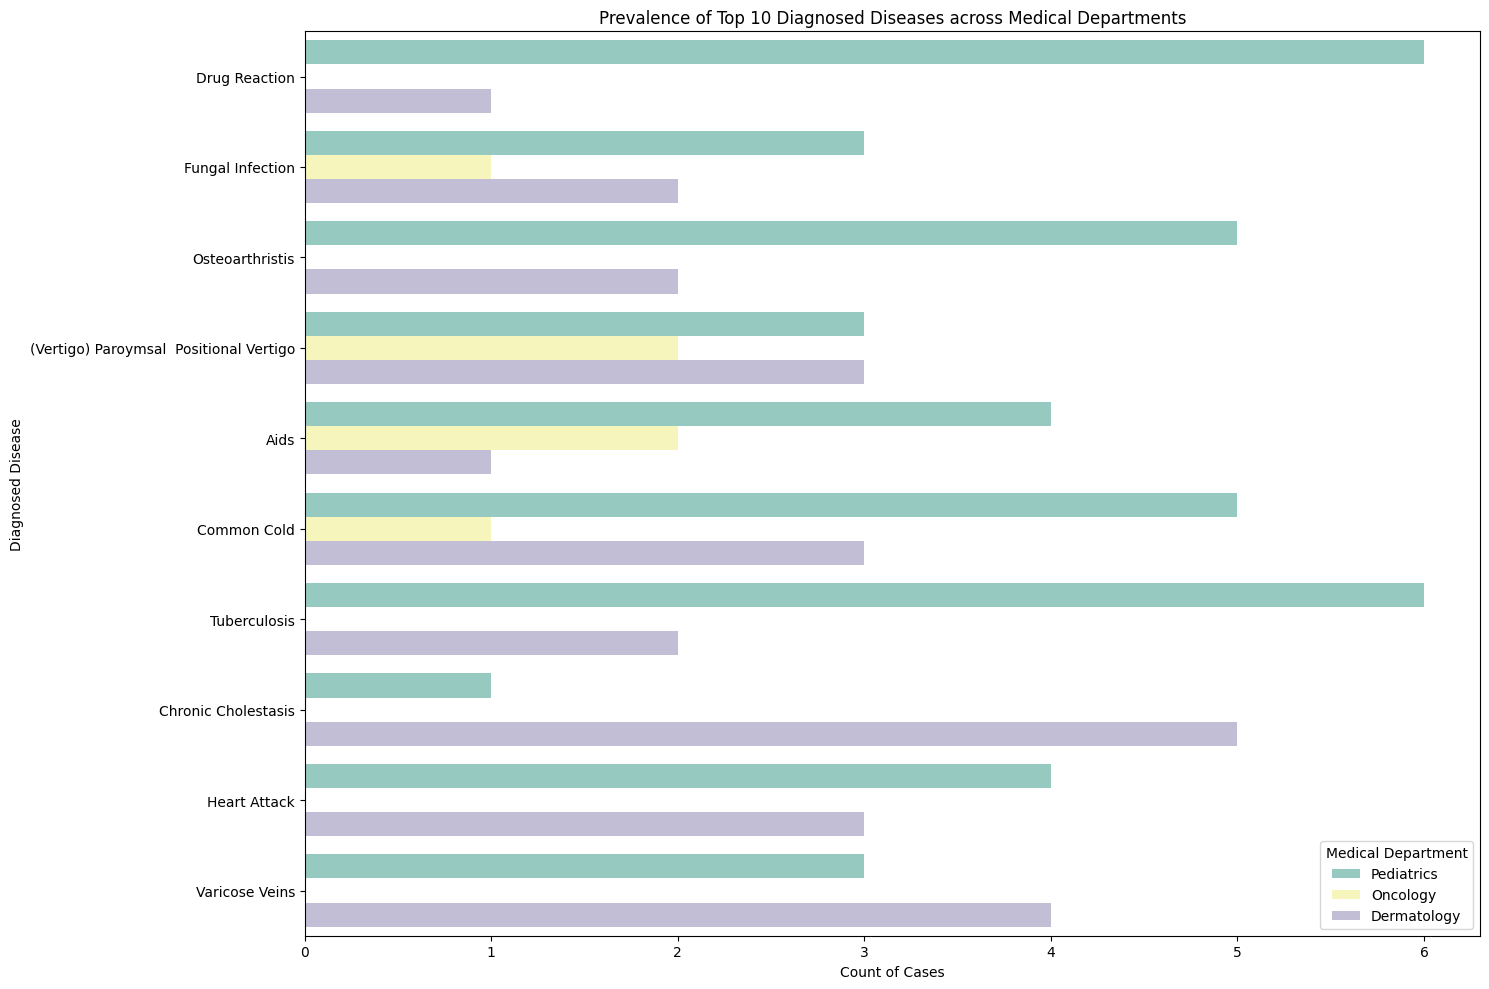

In [26]:
# Filter for the top 10 most frequent diseases 
plt.figure(figsize=(15,10))
top_10_diseases = df_healthcare['Disease'].value_counts().nlargest(10).index
df_top_diseases = df_healthcare[df_healthcare['Disease'].isin(top_10_diseases)]

# Plotting only the top 10 with clear spacing
sns.countplot(data=df_top_diseases, y='Disease', hue='specialization', palette='Set3')
plt.title('Prevalence of Top 10 Diagnosed Diseases across Medical Departments')
plt.ylabel('Diagnosed Disease')
plt.xlabel('Count of Cases')
plt.legend(title='Medical Department', loc='lower right')
plt.tight_layout()
plt.show()

Symptom Co-occurrence Matrix

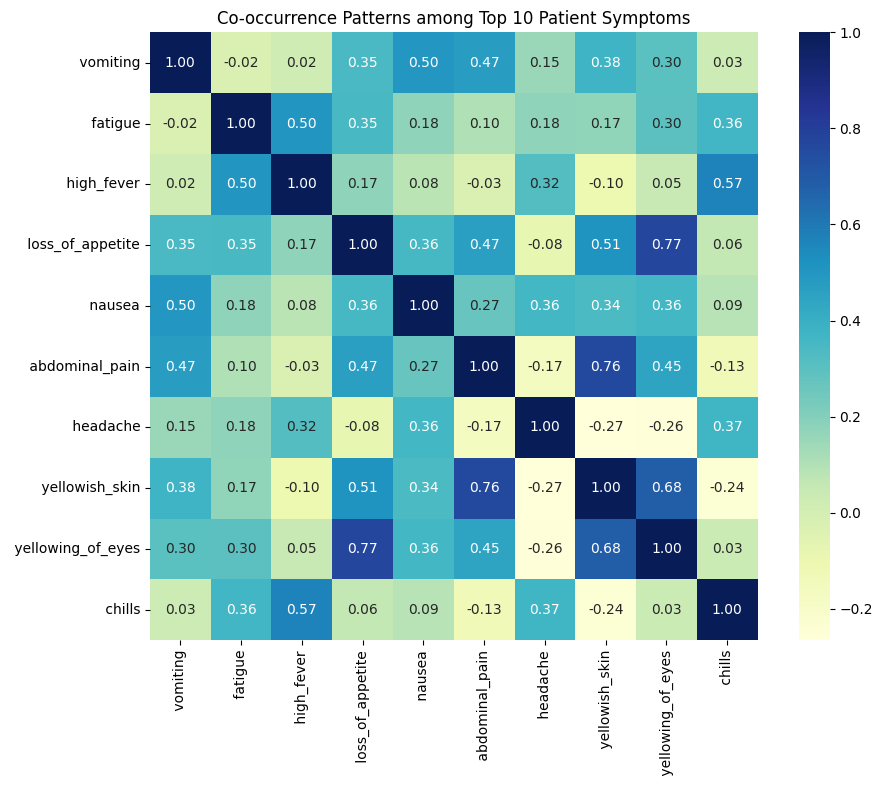

In [27]:
plt.figure(figsize=(10, 8))

# Select top 10 most frequent symptoms dynamically
symptom_cols = [col for col in df_healthcare.columns if df_healthcare[col].dtype == 'int64' and col != 'years_experience']
top_symptoms = df_healthcare[symptom_cols].sum().nlargest(10).index

# Compute correlation and plot heatmap
sns.heatmap(df_healthcare[top_symptoms].corr(), annot=True, cmap='YlGnBu', fmt='.2f', square=True)
plt.title('Co-occurrence Patterns among Top 10 Patient Symptoms')
plt.tight_layout()
plt.show()

Feature Engineering

In [28]:
# Calculate total historical appointments per patient to capture activity levels
patient_booking_counts = df_healthcare['patient_id'].value_counts()
df_healthcare['patient_appointment_count'] = df_healthcare['patient_id'].map(patient_booking_counts)

print(f"Successfully engineered 'patient_appointment_count' feature! Range: {df_healthcare['patient_appointment_count'].min()} to {df_healthcare['patient_appointment_count'].max()} bookings.")

Successfully engineered 'patient_appointment_count' feature! Range: 2 to 10 bookings.


Data Preprocessing

In [29]:
# 1. Handle "Not Available" in hospital_rating and convert to numeric
# We will replace 'Not Available' with the median rating of the known hospitals to keep it stable
known_ratings = df_healthcare[df_healthcare['hospital_rating'] != 'Not Available']['hospital_rating'].astype(float)
median_rating = int(known_ratings.median())

df_healthcare['hospital_rating_clean'] = df_healthcare['hospital_rating'].replace('Not Available', median_rating).astype(int)

In [30]:
# 2. Encode Binary Categorical Feature: gender (F -> 0, M -> 1)
df_healthcare['gender_encoded'] = df_healthcare['gender'].map({'F': 0, 'M': 1})

In [31]:
# 3. Encode Ordinal Categorical Feature: patient_experience
# Map experience levels to a clean logical numeric scale for the recommendation logic
experience_mapping = {
    'Below the national average': 1,
    'Same as the national average': 2,
    'Above the national average': 3,
    'Not available': 2 # Assign the neutral/average level for missing experience logs
}
df_healthcare['patient_experience_encoded'] = df_healthcare['patient_experience'].map(experience_mapping)

In [32]:
print("=" * 60)
print(" DATA PREPROCESSING COMPLETED Successfully!")
print("=" * 60)
print(f"• 'hospital_rating_clean' processed. Missing replaced with median: {median_rating}")
print(f"• 'gender' successfully encoded into 'gender_encoded'.")
print(f"• 'patient_experience' successfully mapped into 'patient_experience_encoded'.")
print(f"• Final usable shape for analytics/modeling: {df_healthcare.shape}")
print("=" * 60)

 DATA PREPROCESSING COMPLETED Successfully!
• 'hospital_rating_clean' processed. Missing replaced with median: 3
• 'gender' successfully encoded into 'gender_encoded'.
• 'patient_experience' successfully mapped into 'patient_experience_encoded'.
• Final usable shape for analytics/modeling: (200, 155)


Advanced Feature Selection & Train-Test Split Pipeline

In [33]:
# 1. Dynamically extract all 131 binary symptom column names safely
# We exclude any operational numeric columns to prevent duplicates
operational_cols = ['years_experience', 'patient_appointment_count', 'gender_encoded', 'hospital_rating_clean', 'patient_experience_encoded']
symptom_features = [col for col in df_healthcare.columns if df_healthcare[col].dtype == 'int64' and col not in operational_cols]

# 2. Combine all baseline patient profile & interaction features for matrix X
core_features = ['age', 'gender_encoded', 'patient_appointment_count']
X_columns = symptom_features + core_features

X = df_healthcare[X_columns]

# 3. Set the target variable y to the actual correct medical specialty
y = df_healthcare['Specialist']

# 4. Perform the Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

In [34]:
print("=" * 60)
print("TRAIN-TEST SPLIT COMPLETED SUCCESSFULLY!")
print("=" * 60)
print(f"• Total Features selected for X: {X.shape[1]} columns")
print(f"  (Includes 131 Symptoms + Age + Gender + Appointment History)")
print(f"• Target variable y selected : '{y.name}'")
print("-" * 60)
print(f"• X_train Shape (Training Features) : {X_train.shape}")
print(f"• y_train Shape (Training Target)   : {y_train.shape}")
print(f"• X_test Shape  (Testing Features)  : {X_test.shape}")
print(f"• y_test Shape  (Testing Target)    : {y_test.shape}")
print("=" * 60)

TRAIN-TEST SPLIT COMPLETED SUCCESSFULLY!
• Total Features selected for X: 134 columns
  (Includes 131 Symptoms + Age + Gender + Appointment History)
• Target variable y selected : 'Specialist'
------------------------------------------------------------
• X_train Shape (Training Features) : (160, 134)
• y_train Shape (Training Target)   : (160,)
• X_test Shape  (Testing Features)  : (40, 134)
• y_test Shape  (Testing Target)    : (40,)


Model Training

In [35]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [36]:
cat_model = CatBoostClassifier(random_state=42, verbose=0) # verbose=0 turns off the long training logs
cat_model.fit(X_train, y_train)

CatBoostClassifier(random_state=42, verbose=0)

In [37]:
xgb_model = XGBClassifier(random_state=42, enable_categorical=True) # enabling string/category mapping cleanly

# For XGBoost to handle text target classes automatically, we use a quick label encoder lookup safely inside python
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)
xgb_model.fit(X_train, y_train_encoded)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

Model Evaluation Baseline


--- Random Forest Baseline Report ---
Training Accuracy : 1.0000
Testing Accuracy  : 1.0000

Classification Report:
                    precision    recall  f1-score   support

         Allergist       1.00      1.00      1.00         2
      Cardiologist       1.00      1.00      1.00         2
     Dermatologist       1.00      1.00      1.00         5
   Endocrinologist       1.00      1.00      1.00         2
Gastroenterologist       1.00      1.00      1.00         4
      Gynecologist       1.00      1.00      1.00         1
      Hepatologist       1.00      1.00      1.00         7
  Internal Medcine       1.00      1.00      1.00         2
       Neurologist       1.00      1.00      1.00         2
       Osteopathic       1.00      1.00      1.00         1
  Otolaryngologist       1.00      1.00      1.00         3
      Pediatrician       1.00      1.00      1.00         1
      Phlebologist       1.00      1.00      1.00         1
     Pulmonologist       1.00      1.00   

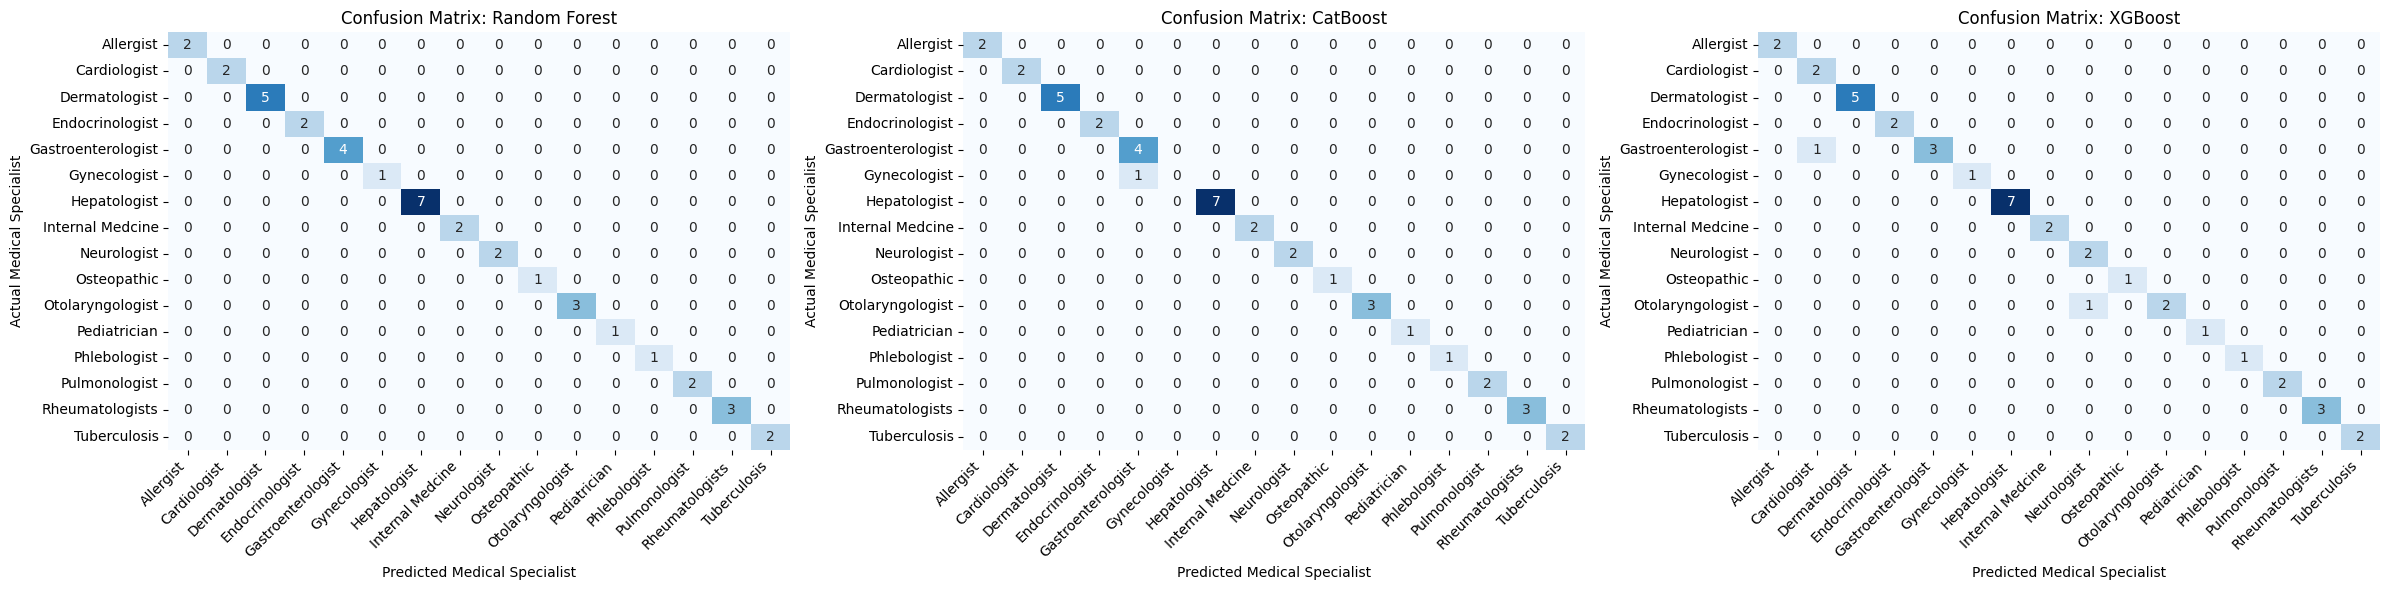

In [38]:
models = {
    'Random Forest': (rf_model, False), # (model, is_xgb)
    'CatBoost': (cat_model, False),
    'XGBoost': (xgb_model, True)
}

baseline_results = []
plt.figure(figsize=(24, 6))

# Extract clean unique classes for confusion matrix tracking dynamically
unique_labels = np.unique(y_test)

for i, (name, (model, is_xgb)) in enumerate(models.items()):
    
    # Evaluate text variables vs encoded integer classes carefully for XGBoost
    if is_xgb:
        train_acc = model.score(X_train, y_train_encoded)
        test_acc = model.score(X_test, y_test_encoded)
        y_pred_encoded = model.predict(X_test)
        y_pred = le.inverse_transform(y_pred_encoded) # Convert back to clinical names for reports
    else:
        train_acc = model.score(X_train, y_train)
        test_acc = model.score(X_test, y_test)
        y_pred = model.predict(X_test)
        
    # Standard multi-class scoring parameters 
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    
    baseline_results.append([name, acc, prec, rec, f1])
    
    print(f"\n{ '=' * 40 }")
    print(f"--- {name} Baseline Report ---")
    print(f"{ '=' * 40 }")
    print(f"Training Accuracy : {train_acc:.4f}")
    print(f"Testing Accuracy  : {test_acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    # Plotting the customized Medical Confusion Matrix
    plt.subplot(1, 3, i + 1)
    cm = confusion_matrix(y_test, y_pred, labels=unique_labels)
    
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=unique_labels,
        yticklabels=unique_labels
    )
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('Actual Medical Specialist')
    plt.xlabel('Predicted Medical Specialist')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

results_before_LDA = pd.DataFrame(
    baseline_results, 
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
)

Dimensionality Reduction using LDA

In [39]:
# ==========================================================
# Dimensionality Reduction using LDA (Dynamic Components Calculation)
# ==========================================================
# 1. Calculate maximum valid LDA components dynamically: min(n_features, n_classes - 1)
n_classes = y_train.nunique()
max_lda_components = min(X_train.shape[1], n_classes - 1)

# 2. Initialize LDA dynamically
lda = LDA(n_components=max_lda_components)

# 3. Fit and Transform on Training Data, Transform on Testing Data
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

print("=" * 60)
print("LDA DIMENSIONALITY REDUCTION COMPLETED SUCCESSFULLY!")
print("=" * 60)
print(f"• Original Feature Dimensions : {X_train.shape[1]} columns")
print(f"• Target Classes Count        : {n_classes} unique specialties")
print(f"• Dynamically Computed LDA    : {X_train_lda.shape[1]} components")
print("=" * 60)

# ==========================================================
# Retrain Models on LDA Components
# ==========================================================

# Retrain Random Forest
rf_lda = RandomForestClassifier(random_state=42)
rf_lda.fit(X_train_lda, y_train)

# Retrain CatBoost
cat_lda = CatBoostClassifier(random_state=42, verbose=0)
cat_lda.fit(X_train_lda, y_train)

# Retrain XGBoost
xgb_lda = XGBClassifier(random_state=42, enable_categorical=True)
xgb_lda.fit(X_train_lda, y_train_encoded)

# Evaluate Models Post-LDA
lda_models = {
    'Random Forest (LDA)': (rf_lda, False),
    'CatBoost (LDA)': (cat_lda, False),
    'XGBoost (LDA)': (xgb_lda, True)
}

lda_results = []

for name, (model, is_xgb) in lda_models.items():
    if is_xgb:
        train_acc = model.score(X_train_lda, y_train_encoded)
        test_acc = model.score(X_test_lda, y_test_encoded)
        y_pred_encoded = model.predict(X_test_lda).astype(int) # Safe integer cast
        y_pred = le.inverse_transform(y_pred_encoded)
    else:
        train_acc = model.score(X_train_lda, y_train)
        test_acc = model.score(X_test_lda, y_test)
        y_pred = model.predict(X_test_lda)
        
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    
    lda_results.append([name, acc, prec, rec, f1])

# Create summary DataFrame for Post-LDA Results
results_after_LDA = pd.DataFrame(
    lda_results, 
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
)

# ==========================================================
# Comparative Display: Before vs After LDA
# ==========================================================
print("\n" + "=" * 60)
print("ACCURACY COMPARISON: BEFORE VS AFTER LDA")
print("=" * 60)

comparison_df = pd.concat([results_before_LDA, results_after_LDA], ignore_index=True)
print(comparison_df.to_string(index=False))
print("=" * 60)

LDA DIMENSIONALITY REDUCTION COMPLETED SUCCESSFULLY!
• Original Feature Dimensions : 134 columns
• Target Classes Count        : 16 unique specialties
• Dynamically Computed LDA    : 15 components

ACCURACY COMPARISON: BEFORE VS AFTER LDA
              Model  Accuracy  Precision   Recall  F1-Score
      Random Forest     1.000   1.000000 1.000000  1.000000
           CatBoost     0.975   0.925000 0.937500  0.930556
            XGBoost     0.950   0.958333 0.963542  0.953571
Random Forest (LDA)     1.000   1.000000 1.000000  1.000000
     CatBoost (LDA)     1.000   1.000000 1.000000  1.000000
      XGBoost (LDA)     0.950   0.975000 0.982143  0.973958


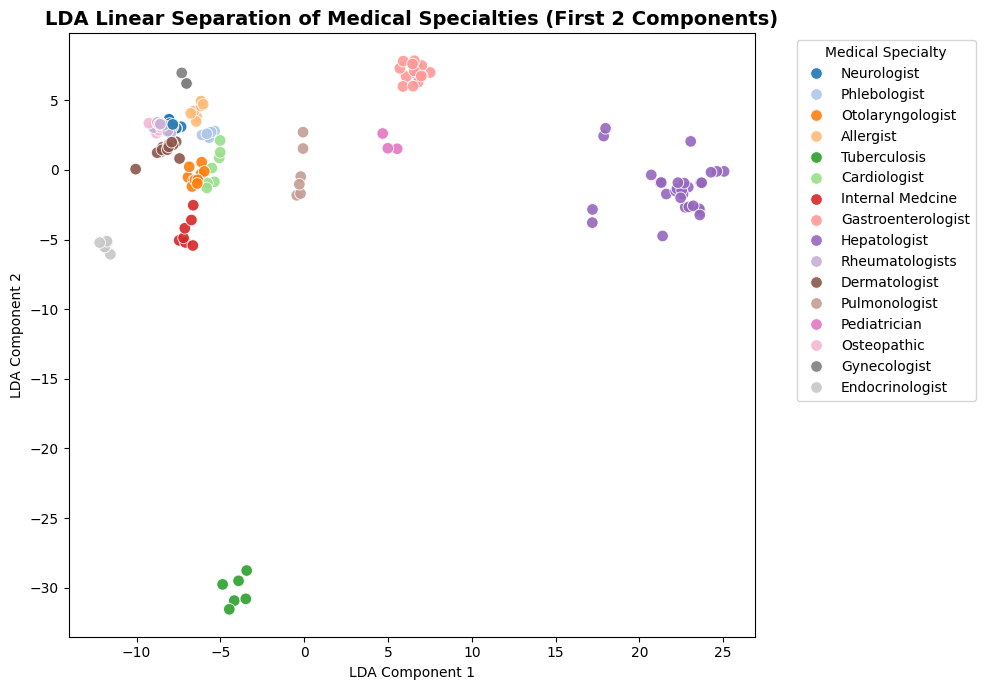

In [40]:
# Visualize the First 2 LDA Components
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_train_lda[:, 0], 
    y=X_train_lda[:, 1], 
    hue=y_train, 
    palette='tab20', 
    s=70, 
    alpha=0.9
)

plt.title('LDA Linear Separation of Medical Specialties (First 2 Components)', fontsize=14, fontweight='bold')
plt.xlabel('LDA Component 1')
plt.ylabel('LDA Component 2')
plt.legend(title='Medical Specialty', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Visualization: Confusion Matrices Post-LDA Dimensionality Reduction

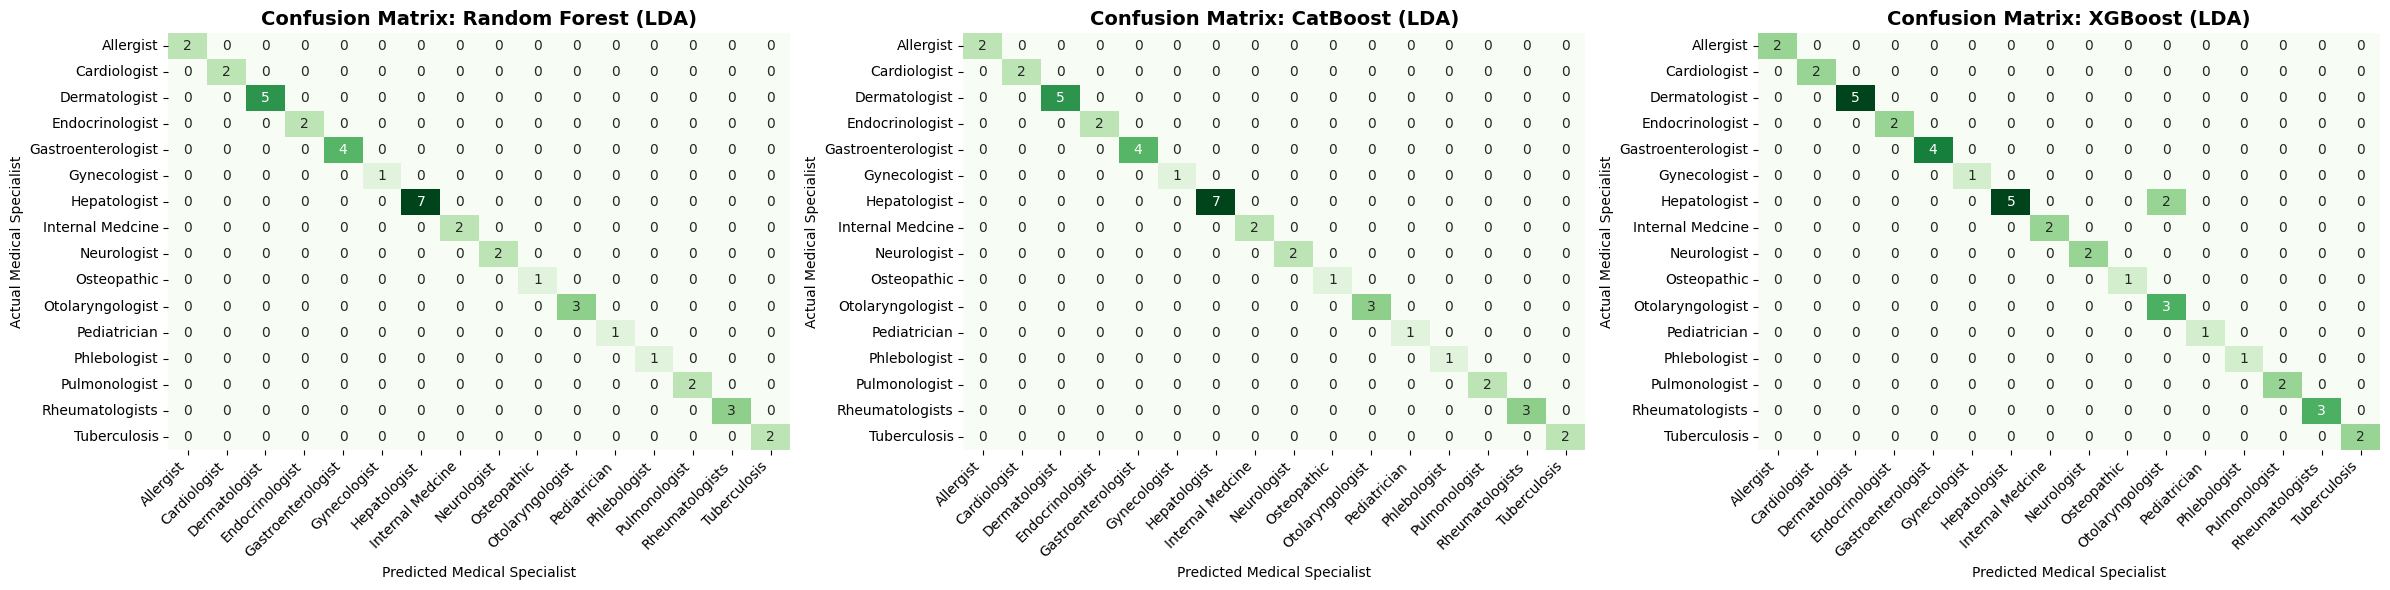

In [41]:
plt.figure(figsize=(24, 6))

# Extract clean unique classes for confusion matrix tracking dynamically
unique_labels = np.unique(y_test)

for i, (name, (model, is_xgb)) in enumerate(lda_models.items()):
    
    # Generate predictions using the LDA transformed test features
    if is_xgb:
        y_pred_encoded = model.predict(X_test_lda).astype(int) 
        y_pred = le.inverse_transform(y_pred_encoded)
    else:
        y_pred = model.predict(X_test_lda)
        
    # Plotting the Post-LDA Medical Confusion Matrix
    plt.subplot(1, 3, i + 1)
    cm = confusion_matrix(y_test, y_pred, labels=unique_labels)
    
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Greens', cbar=False,
        xticklabels=unique_labels,
        yticklabels=unique_labels
    )
    plt.title(f'Confusion Matrix: {name}', fontsize=14, fontweight='bold')
    plt.ylabel('Actual Medical Specialist')
    plt.xlabel('Predicted Medical Specialist')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Personalized Healthcare Recommendation System

In [42]:
# ==========================================================
# Architecture: Two-Stage Recommendation Pipeline
# Stage 1: Machine Learning Clinical Routing (Classification)
# Stage 2: Quality-Weighted Provider Ranking (Filtering & Scoring)
# ==========================================================

def get_personalized_recommendations(patient_id, model=rf_lda, lda_transformer=lda, df_master=df_healthcare, top_n=3):
    """
    Executes a personalized two-stage healthcare recommendation pipeline for a given patient_id.
    
    Parameters:
    - patient_id (str): Unique Identifier of the patient (e.g., 'P012').
    - model: Trained ML Classifier (Default: Random Forest with LDA).
    - lda_transformer: Fitted LDA Dimensionality Reduction object.
    - df_master (DataFrame): Master schema containing full patient & provider interactions.
    - top_n (int): Number of top recommended healthcare providers to return.
    """
    
    # Extract patient records matching the patient_id
    patient_records = df_master[df_master['patient_id'] == patient_id]
    
    if patient_records.empty:
        print(f"Patient ID '{patient_id}' not found in the master database!")
        return None
        
    # Take the most recent interaction/profile row for demographics
    patient_record = patient_records.iloc[[0]].copy()
    
    # ----------------------------------------------------------
    # STAGE 1: Clinical Symptom Analysis & Specialty Prediction
    # ----------------------------------------------------------
    patient_features = patient_record[X_columns]
    
    # Reduce symptom dimensionality using fitted dynamic LDA
    patient_features_lda = lda_transformer.transform(patient_features)
    
    # Predict target medical specialty using trained AI model
    predicted_specialty = model.predict(patient_features_lda)[0]
    
    # Extract model diagnostic confidence
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(patient_features_lda)[0]
        confidence = np.max(probabilities) * 100
    else:
        confidence = 100.0

    # Display Stage 1 Diagnostic Summary
    print("=" * 75)
    print("PERSONALIZED HEALTHCARE RECOMMENDATION SYSTEM")
    print("=" * 75)
    print(f"• Patient ID                   : {patient_record['patient_id'].values[0]}")
    print(f"• Patient Demographics         : Age {patient_record['age'].values[0]} | Gender Code: {patient_record['gender_encoded'].values[0]}")
    print(f"• Historical Activity Level    : {patient_record['patient_appointment_count'].values[0]} Previous Bookings")
    print("-" * 75)
    print("STAGE 1: CLINICAL DIAGNOSIS & ROUTING")
    print(f"• Predicted Required Specialist : {str(predicted_specialty).upper()}")
    print(f"• Model Diagnostic Confidence   : {confidence:.2f}%")
    print("=" * 75)
    
    # ----------------------------------------------------------
    # STAGE 2: Personalized Provider Filtering & Weighted Ranking
    # ----------------------------------------------------------
    # 1. Filter database for providers matching predicted specialty
    matched_providers = df_master[
        df_master['Specialist'].astype(str).str.strip().str.title() == str(predicted_specialty).strip().title()
    ].copy()
    
    # Fallback to general specialization if exact specialist match is empty
    if matched_providers.empty:
        matched_providers = df_master[
            df_master['specialization'].astype(str).str.strip().str.title() == str(predicted_specialty).strip().title()
        ].copy()

    if matched_providers.empty:
        print(f"No specific doctors currently available for specialty '{predicted_specialty}'.")
        return None

    # 2. Compute Multi-Criteria Composite Quality Score (Scale 0 to 5)
    max_doc_exp = df_master['years_experience'].max()
    
    matched_providers['composite_score'] = (
        (matched_providers['hospital_rating_clean'] * 0.40) +
        (matched_providers['patient_experience_encoded'] * 0.30) +
        ((matched_providers['years_experience'] / max_doc_exp) * 5.0 * 0.30)
    )
    
    # 3. Deduplicate providers & sort by highest composite score
    ranked_recommendations = (
        matched_providers.sort_values(by='composite_score', ascending=False)
        .drop_duplicates(subset=['doctor_id', 'hospital_name'])
        .head(top_n)
    )
    
    # Display Stage 2 Provider Recommendations
    print(f"STAGE 2: TOP {len(ranked_recommendations)} RECOMMENDED DOCTORS & CLINICS")
    print("-" * 75)
    
    for rank, (_, provider) in enumerate(ranked_recommendations.iterrows(), 1):
        print(f"Option #{rank}:")
        print(f"  Doctor ID / Branch   : {provider['doctor_id']} ({provider['hospital_branch']})")
        print(f"  Clinical Experience   : {provider['years_experience']} Years")
        print(f"  Facility Name         : {provider['hospital_name']}")
        print(f"  CMS Hospital Rating   : {provider['hospital_rating_clean']} / 5")
        print(f"  Patient Satisfaction  : {provider['patient_experience']}")
        print(f"  Service Quality Index : {provider['composite_score']:.2f} / 5.00")
        print("-" * 75)
        
    return ranked_recommendations

Test Execution With Sample Patient

In [43]:
# Run recommendation test for Patient at index 5
recommendations_df = get_personalized_recommendations(patient_id='P012', model=rf_lda, top_n=3)

PERSONALIZED HEALTHCARE RECOMMENDATION SYSTEM
• Patient ID                   : P012
• Patient Demographics         : Age 35 | Gender Code: 0
• Historical Activity Level    : 10 Previous Bookings
---------------------------------------------------------------------------
STAGE 1: CLINICAL DIAGNOSIS & ROUTING
• Predicted Required Specialist : OTOLARYNGOLOGIST
• Model Diagnostic Confidence   : 51.00%
STAGE 2: TOP 3 RECOMMENDED DOCTORS & CLINICS
---------------------------------------------------------------------------
Option #1:
  Doctor ID / Branch   : D009 (Central Hospital)
  Clinical Experience   : 26 Years
  Facility Name         : ST ANTHONY HOSPITAL
  CMS Hospital Rating   : 4 / 5
  Patient Satisfaction  : Above the national average
  Service Quality Index : 3.89 / 5.00
---------------------------------------------------------------------------
Option #2:
  Doctor ID / Branch   : D005 (Central Hospital)
  Clinical Experience   : 26 Years
  Facility Name         : PROVIDENCE NEWBER

Save Trained Model

In [44]:
# 1. Save the processed master healthcare dataset
df_healthcare.to_csv("cleaned_healthcare_dataset.csv", index=False)

# 2. Save Trained Random Forest Model, LDA Transformer, and Feature Columns
joblib.dump(rf_lda, "rf_lda_model.pkl")
joblib.dump(lda, "lda_transformer.pkl")
joblib.dump(X_columns, "model_features.pkl")

print(" All model artifacts and cleaned dataset saved successfully!")

 All model artifacts and cleaned dataset saved successfully!


In [45]:
df_healthcare.info(verbose=True ,show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 155 columns):
 #    Column                           Non-Null Count  Dtype         
---   ------                           --------------  -----         
 0    patient_id                       200 non-null    object        
 1    doctor_id                        200 non-null    object        
 2    reason_for_visit                 200 non-null    object        
 3    status                           200 non-null    object        
 4    gender                           200 non-null    object        
 5    date_of_birth                    200 non-null    datetime64[ns]
 6    specialization                   200 non-null    object        
 7    years_experience                 200 non-null    int64         
 8    hospital_branch                  200 non-null    object        
 9    itching                          200 non-null    int64         
 10    skin_rash                       200 non-null   